# ML-labb 3: Tyngdkraft, fjäderkraft och parameterskattning
**Fysik 1 · Rörelse och kraft** &nbsp;·&nbsp; **Gruppmedlemmar:** *dubbelklicka här och skriv era namn*

Idag mäter ni med en **rörelsesensor**. Den skickar ut ljudpulser och mäter hur lång tid ekot tar – så vet den avståndet till föremålet, många gånger per sekund. Ur det räknar den också ut hastigheten.

- **Del A:** En boll som kastas rakt upp. Ur mätdatan skattar ni **tyngdaccelerationen** $g$.
- **Del B:** En fjäder som dras ut av vikter. Ur mätdatan skattar ni **fjäderkonstanten** $k$.
- **Del C (extra):** En vikt som svänger i fjädern.

Att bestämma ett okänt tal i en modell ur mätdata kallas **parameterskattning**. Det är precis det som händer när en maskininlärningsmodell tränas.

**Så arbetar ni:** Läs en del i taget. Kör kodcellerna med ▶ (eller Skift + Enter), alla på samma dator – varje dator har sitt eget minne. Svara på frågorna i textrutorna – dubbelklicka på en ruta för att skriva i den.

| Begrepp | Vad det betyder | Idag |
|---|---|---|
| **Modell** | ett samband som beskriver datan | $v = v_0 + a \cdot t$ för bollen – och ett samband för fjädern som ni hittar själva |
| **Parameter** | ett okänt tal i modellen | $g$ och $k$ |
| **Förlust** | ett mått på hur dåligt modellen stämmer med datan | medelkvadratfelet |
| **Träningsdata** | data som används för att bestämma parametern | de flesta mätpunkterna |
| **Testdata** | data som modellen inte får se – för att kontrollera den | några mätpunkter ni sparar |

**Tid:** del A ungefär 25 minuter, del B ungefär 35 minuter. Del C gör ni om ni hinner.

**Säkerhet:** Ställ alltid en trådkorg eller liknande skydd över sensorn. Kasta lätt – bollen ska inte upp i taket. Håll fötterna borta från vikterna.

In [ ]:
#@title 0. Förbered verktygen – kör den här cellen först { display-mode: "form" }
#@markdown Klicka på ▶ till vänster. Du behöver inte läsa koden – den innehåller verktyg som resten av labben använder.
import io, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.signal import savgol_filter, medfilt

warnings.filterwarnings("ignore")
try:
    from google.colab import files as _colab_files
    I_COLAB = True
except ImportError:
    I_COLAB = False

# ---------- utseende ----------
BLA, TURK, ROD, ORANGE, GRA, INK, LILA = "#2563EB", "#0F8C80", "#DC2626", "#F59E0B", "#94A3B8", "#0F172A", "#7C3AED"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.35,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})


def tal(x, dec=2):
    """Tal med decimalkomma och riktigt minustecken."""
    return f"{x:.{dec}f}".replace(".", ",").replace("-", "−")


def _tick(x, pos=None):
    return ("%g" % round(x, 6)).replace(".", ",").replace("-", "−")


def svenska_axlar(*axlar):
    for ax in axlar:
        ax.xaxis.set_major_formatter(FuncFormatter(_tick))
        ax.yaxis.set_major_formatter(FuncFormatter(_tick))


# ---------- läs in sensorns fil ----------
_NYCKLAR = {
    "t": ["time", "tid"],
    "s": ["position", "läge", "lage", "distance", "avstånd", "avstand", "höjd", "hojd"],
    "v": ["velocity", "hastighet", "speed", "fart"],
}


def _till_tal(serie):
    s = serie.astype(str).str.strip().str.replace("−", "-", regex=False)
    s = s.str.replace(" ", "", regex=False).str.replace(" ", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce")


def _avgransare(rader):
    for tecken in ["\t", ";"]:
        if sum(r.count(tecken) for r in rader) >= len(rader):
            return tecken
    return ","


def _storhet(namn):
    n = namn.lower()
    if "acc" in n:
        return None
    for nyckel, ord_ in _NYCKLAR.items():
        if any(o in n for o in ord_):
            return nyckel
    return None


def _korningsnyckel(namn):
    m = re.search(r"(run\s*#?\s*\d+|körning\s*#?\s*\d+|data\s*set\s*\d+|dataset\s*\d+|mätning\s*\d+)", namn.lower())
    return m.group(1).replace(" ", "") if m else ""


def _enhetsfaktor(namn):
    n = namn.lower()
    if "(cm" in n or "[cm" in n:
        return 0.01
    if "(mm" in n or "[mm" in n:
        return 0.001
    return 1.0


def las_sensorfil(innehall, korning=1):
    """Läser en CSV- eller textfil från en rörelsesensor. Klarar komma, semikolon och tab,
    decimalkomma och filer med flera körningar. Returnerar en tabell med t (s), s (m) och v (m/s)."""
    text = innehall.decode("utf-8-sig", errors="replace") if isinstance(innehall, bytes) else innehall
    rader = [r for r in text.splitlines() if r.strip()]
    start = 0
    for i, r in enumerate(rader[:40]):
        if any(o in r.lower() for o in _NYCKLAR["t"]):
            start = i
            break
    sep = _avgransare(rader[start:start + 10])
    df = pd.read_csv(io.StringIO("\n".join(rader[start:])), sep=sep, dtype=str, engine="python")
    kolumner = {}
    for kol in df.columns:
        storhet = _storhet(kol)
        if storhet:
            kolumner.setdefault(_korningsnyckel(kol), {}).setdefault(storhet, kol)
    grupper = [g for g in kolumner.values() if "t" in g and "s" in g]
    if not grupper:  # inga igenkända rubriker: anta tid, läge, hastighet i ordning
        kols = list(df.columns)
        grupper = [{"t": kols[0], "s": kols[1], **({"v": kols[2]} if len(kols) > 2 else {})}]
    if korning > len(grupper):
        raise ValueError(f"Filen innehåller {len(grupper)} körning(ar) – välj ett nummer från 1 till {len(grupper)}.")
    g = grupper[korning - 1]
    ut = pd.DataFrame({"t": _till_tal(df[g["t"]]), "s": _till_tal(df[g["s"]]) * _enhetsfaktor(g["s"])})
    if "v" in g:
        ut["v"] = _till_tal(df[g["v"]]) * _enhetsfaktor(g["v"])
    ut = ut.dropna(subset=["t", "s"]).reset_index(drop=True)
    if "v" not in ut or ut["v"].isna().all():
        ut["v"] = np.gradient(ut["s"].to_numpy(), ut["t"].to_numpy())
    ut["v"] = ut["v"].interpolate(limit_direction="both")
    if len(grupper) > 1:
        print(f"Filen innehåller {len(grupper)} körningar – jag använder körning {korning}.")
    return ut


def hamta_data(anvand_exempel, exempel, korning=1):
    if anvand_exempel:
        df = exempel()
        print(f"Exempeldata: {len(df)} mätpunkter.")
        return df
    if not I_COLAB:
        raise RuntimeError("Uppladdning fungerar bara i Google Colab. Kryssa i exempeldata för att testa.")
    uppladdat = _colab_files.upload()
    if not uppladdat:
        raise RuntimeError("Ingen fil laddades upp. Kör cellen igen och välj er CSV-fil.")
    namn, innehall = next(iter(uppladdat.items()))
    df = las_sensorfil(innehall, korning)
    print(f"Läste {len(df)} mätpunkter från {namn}.")
    return df


def las_tal(text):
    """Läser tal skrivna med mellanslag emellan. Både 0,52 och 0.52 fungerar."""
    delar = [d.strip().rstrip(",") for d in re.split(r"[;\s]+", str(text).strip()) if d.strip().rstrip(",")]
    try:
        return [float(d.replace(",", ".").replace("−", "-")) for d in delar]
    except ValueError:
        raise ValueError("Kunde inte läsa talen. Skriv dem med mellanslag emellan, till exempel: 0,520 0,500 0,480")


# ---------- exempeldata (om er egen mätning inte fungerar) ----------
def _sensorbrus(t, s, rng, brus=0.0015):
    s_m = np.round(s + rng.normal(0, brus, len(s)), 3)
    v_m = savgol_filter(s_m, 5, 2, deriv=1, delta=t[1] - t[0])
    return s_m, v_m


def exempel_bollkast(seed=3):
    rng = np.random.default_rng(seed)
    f, g, c = 30.0, 9.82, 0.02                   # 30 mätningar/s, luftmotstånd c·v²
    t = np.arange(0, 3.0, 1 / f)
    s = np.zeros_like(t)
    t_kast, t_slapp, s_hand, s_slapp, v0 = 0.60, 0.80, 0.52, 0.72, 3.4
    dt, tt, ss, vv = 1e-4, [t_slapp], [s_slapp], [v0]
    while ss[-1] >= s_slapp - 0.04 or tt[-1] < t_slapp + 0.1:
        v = vv[-1]
        a = -g - c * v * abs(v)
        vv.append(v + a * dt); ss.append(ss[-1] + v * dt); tt.append(tt[-1] + dt)
    t_fang, s_fang, v_fang = tt[-1], ss[-1], vv[-1]

    def hermite(tau, T, s0, s1, v0_, v1_):
        u = tau / T
        h00, h10, h01, h11 = 2*u**3 - 3*u**2 + 1, u**3 - 2*u**2 + u, -2*u**3 + 3*u**2, u**3 - u**2
        return h00 * s0 + h10 * T * v0_ + h01 * s1 + h11 * T * v1_

    for i, ti in enumerate(t):
        if ti < t_kast:
            s[i] = s_hand + 0.004 * np.sin(2 * np.pi * 1.3 * ti)
        elif ti < t_slapp:
            s[i] = hermite(ti - t_kast, t_slapp - t_kast, s_hand, s_slapp, 0, v0)
        elif ti < t_fang:
            s[i] = np.interp(ti, tt, ss)
        elif ti < t_fang + 0.2:
            s[i] = hermite(ti - t_fang, 0.2, s_fang, s_fang - 0.14, v_fang, 0)
        else:
            s[i] = s_fang - 0.14 + 0.003 * np.sin(2 * np.pi * 1.1 * ti)
    s_m, v_m = _sensorbrus(t, s, rng)
    for i in (9, 80):                            # två felmätningar när bollen ligger i händerna
        s_m[i] = 1.9 if i == 9 else 0.21
    v_m = savgol_filter(s_m, 5, 2, deriv=1, delta=1 / f)
    return pd.DataFrame({"t": np.round(t, 3), "s": s_m, "v": np.round(v_m, 3)})


def exempel_fjader(seed=5):
    rng = np.random.default_rng(seed)
    k, g, ref = 24.5, 9.82, 0.520
    massa = np.array([0, 50, 100, 150, 200, 250, 300])
    lage = np.round(ref - massa / 1000 * g / k + rng.normal(0, 0.001, len(massa)), 3)
    lage[0] = ref
    return list(massa), list(lage)


def exempel_svangning(seed=7):
    rng = np.random.default_rng(seed)
    f, k, m, gamma = 30.0, 24.5, 0.26, 0.15
    t = np.arange(0, 5.0, 1 / f)
    jamvikt = 0.520 - 0.200 * 9.82 / k
    w = np.sqrt(k / m - gamma**2)
    t0, A = 0.5, 0.025
    s = np.where(t < t0, jamvikt - A, jamvikt - A * np.exp(-gamma * (t - t0)) * np.cos(w * (t - t0)))
    s_m, v_m = _sensorbrus(t, s, rng, 0.001)
    return pd.DataFrame({"t": np.round(t, 3), "s": s_m, "v": np.round(v_m, 3)})


# ---------- analys ----------
def foreslag_flygintervall(t, s):
    """Föreslår tiden då bollen flyger fritt: området kring toppen där läget följer en parabel."""
    sf = medfilt(s, 5)
    topp = int(np.argmax(sf))
    lo, hi = max(topp - 4, 0), min(topp + 5, len(t))
    for _ in range(len(t)):
        flyttat = False
        for sida in ("v", "h"):
            nlo, nhi = (lo - 1, hi) if sida == "v" else (lo, hi + 1)
            if nlo < 0 or nhi > len(t):
                continue
            p = np.polyfit(t[nlo:nhi], s[nlo:nhi], 2)
            r = s[nlo:nhi] - np.polyval(p, t[nlo:nhi])
            kant = r[0] if sida == "v" else r[-1]
            if abs(kant) < 0.006 and -14 < 2 * p[0] < -6:
                lo, hi, flyttat = nlo, nhi, True
        if not flyttat:
            break
    lo, hi = lo + 2, hi - 3
    return float(t[lo]), float(t[hi])


def forlust(k, dl, F):
    """Medelkvadratfelet: medelvärdet av (modellens kraft − uppmätt kraft)²."""
    return float(np.mean((k * np.asarray(dl) - np.asarray(F)) ** 2))


def basta_k(dl, F):
    """Det k som ger minst förlust för modellen F = k·Δl."""
    dl, F = np.asarray(dl), np.asarray(F)
    return float(np.sum(F * dl) / np.sum(dl * dl))


def sig(x, n=3):
    """Tal med ungefär n värdesiffror, utan tiopotenser."""
    if x == 0:
        return "0"
    d = max(0, n - 1 - int(np.floor(np.log10(abs(x)))))
    return tal(x, d)


def robust_y(ax, y, marginal=0.25):
    """Sätter y-axeln efter de flesta punkterna, så att enstaka felmätningar inte förstör bilden."""
    y = np.asarray(y)
    lo, hi = np.percentile(y, 2), np.percentile(y, 98)
    d = (hi - lo) or 0.1
    lo, hi = lo - marginal * d, hi + marginal * d
    ax.set_ylim(lo, hi)
    return int(np.sum((y < lo) | (y > hi)))


print("Klart! Verktygen är laddade." + ("" if I_COLAB else " (Du kör utanför Colab – använd exempeldata.)"))

---
## Del A – Bollkastet: rörelse och tyngdkraft

### A1. Förutsäg först
Innan ni mäter: skissa på papper hur **läget** $s$ och **hastigheten** $v$ ändras med tiden, från att bollen lämnar händerna tills ni fångar den. Positiv riktning är uppåt.

- Hur ser $s$–$t$-grafen ut?
- Hur ser $v$–$t$-grafen ut? Vad betyder lutningen i den?

**Ert svar:**

### A2. Mät

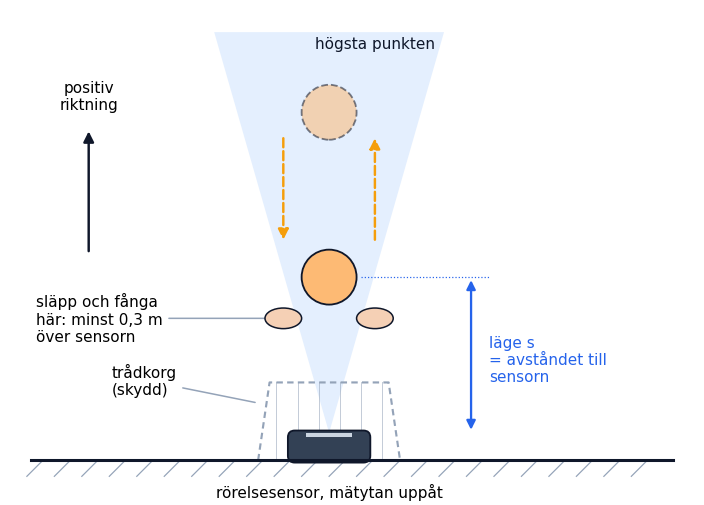

1. Lägg sensorn på golvet med mätytan uppåt och ställ en trådkorg över den.
2. Ställ in sensorn på **30 mätningar per sekund** och en mättid på **5 sekunder**.
3. Håll bollen med båda händerna rakt över sensorn, minst 0,3 m ovanför den. Starta mätningen.
4. Kasta bollen rakt upp, ungefär en halv meter, och fånga den på samma höjd. Håll händerna utanför ljudkonen medan bollen är i luften.
5. Titta på graferna i sensorns program. Gör om mätningen om graferna har hopp eller luckor medan bollen är i luften.
6. Exportera mätningen som en **CSV-fil** och spara den på datorn.

> **Tips:** En stor och tung boll, till exempel en basketboll, ger bäst mätningar.

### A3. Ladda in er mätning
Kör cellen och välj er CSV-fil. Har ni ingen egen mätning kan ni kryssa i **anvand_exempeldata** och köra cellen igen.

In [ ]:
#@title A3. Ladda in data { display-mode: "form" }
anvand_exempeldata = False #@param {type:"boolean"}
korning = 1 #@param {type:"integer"}
#@markdown Ändra *korning* bara om filen innehåller flera mätningar.
data_A = hamta_data(anvand_exempeldata, exempel_bollkast, korning)
tA, sA, vA = data_A["t"].to_numpy(), data_A["s"].to_numpy(), data_A["v"].to_numpy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
ax1.plot(tA, sA, ".", color=INK, ms=4)
ax1.set_ylabel("läge $s$ (m)")
ax1.set_title("Hela mätningen", loc="left", fontsize=12)
ax2.plot(tA, vA, ".", color=BLA, ms=4)
ax2.set_ylabel("hastighet $v$ (m/s)")
ax2.set_xlabel("tid $t$ (s)")
utanfor = robust_y(ax1, sA) + robust_y(ax2, vA)
svenska_axlar(ax1, ax2)
plt.tight_layout()
plt.show()
if utanfor:
    print(f"{utanfor} punkt(er) hamnade utanför bilden. Det är troligen felmätningar, när sensorn tappade bollen.")

### A4. Datarensning: välj tiden då bollen är i luften
Sensorn mäter hela tiden – också när bollen ligger i händerna. De mätpunkterna följer inte modellen för fritt fall. Välj tidsintervallet när bollen flyger fritt: där $v$–$t$-grafen är en **rät linje**.

> **Koppling till maskininlärning:** Att välja ut rätt data kallas *datarensning*. En modell kan aldrig bli bättre än datan den tränas på.

Låt båda fälten vara 0 första gången – då föreslår datorn ett intervall. Titta sedan i graferna och justera själva. Decimalkomma går bra, till exempel 0,85.

In [ ]:
#@title A4. Välj intervall { display-mode: "form" }
t_start = "0" #@param {type:"string"}
t_slut = "0" #@param {type:"string"}
t_start, t_slut = las_tal(t_start)[0], las_tal(t_slut)[0]
if t_slut <= t_start:
    t_start, t_slut = foreslag_flygintervall(tA, sA)
    print(f"Datorns förslag: t_start = {tal(t_start)} s och t_slut = {tal(t_slut)} s.")
    print("Vill ni ändra? Skriv in egna värden i fälten ovan och kör cellen igen.")
urval = (tA >= t_start) & (tA <= t_slut)
print(f"Valt intervall: {tal(t_start)}–{tal(t_slut)} s, {urval.sum()} mätpunkter.")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
for ax, y, farg, namn in ((ax1, sA, INK, "läge $s$ (m)"), (ax2, vA, BLA, "hastighet $v$ (m/s)")):
    ax.axvspan(t_start, t_slut, color=ORANGE, alpha=0.15, lw=0)
    ax.plot(tA[~urval], y[~urval], ".", color=GRA, ms=4, label="bortvalda punkter")
    ax.plot(tA[urval], y[urval], ".", color=farg, ms=6, label="valda punkter")
    ax.set_ylabel(namn)
    robust_y(ax, y)
ax2.set_xlabel("tid $t$ (s)")
ax1.legend(loc="upper right")
svenska_axlar(ax1, ax2)
plt.tight_layout()
plt.show()

### A5. Skatta $g$
När bollen flyger fritt gäller modellen

$$v = v_0 + a \cdot t$$

Modellen har två parametrar: startvärdet $v_0$ och accelerationen $a$. Datorn letar upp de värden som gör att linjen hamnar så nära mätpunkterna som möjligt. Accelerationen är **lutningen** i $v$–$t$-grafen, alltså kvoten mellan kateterna i triangeln: $a = \dfrac{\Delta v}{\Delta t}$.

Datorn gör också en andra skattning ur lägesdatan, med modellen $s = s_0 + v_0 \cdot t + \dfrac{a \cdot t^2}{2}$ (en parabel).

In [ ]:
#@title A5. Skatta g { display-mode: "form" }
t_u, s_u, v_u = tA[urval], sA[urval], vA[urval]
a, v0 = np.polyfit(t_u, v_u, 1)
c2, c1, c0 = np.polyfit(t_u, s_u, 2)
g_v, g_s = abs(a), abs(2 * c2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
tt = np.linspace(t_u.min(), t_u.max(), 200)
ax1.plot(t_u, v_u, "o", color=BLA, ms=5, label="mätpunkter")
ax1.plot(tt, v0 + a * tt, color=INK, lw=2, label="modell: $v = v_0 + a \\cdot t$")
spann = t_u.max() - t_u.min()
steg = 0.1 if spann >= 0.35 else 0.05
dt_tri = max(steg, np.floor(0.6 * spann / steg) * steg)
t1 = t_u.min() + 0.15 * spann
t2 = t1 + dt_tri
v1, v2 = v0 + a * t1, v0 + a * t2
ax1.plot([t1, t2, t2], [v1, v1, v2], color=ORANGE, lw=2, ls="--")
ax1.annotate(f"Δt = {tal(t2 - t1)} s", ((t1 + t2) / 2, v1), textcoords="offset points", xytext=(0, 7), ha="center", color="#B45309")
ax1.annotate(f"Δv = {tal(v2 - v1, 3)} m/s", (t2, (v1 + v2) / 2), textcoords="offset points", xytext=(7, 0), va="center", color="#B45309")
ax1.set_title("Lutningen i $v$–$t$-grafen är accelerationen", loc="left", fontsize=11)
ax1.set_xlabel("tid $t$ (s)"); ax1.set_ylabel("hastighet $v$ (m/s)")
ax1.legend(loc="lower left")
ax2.plot(t_u, s_u, "o", color=INK, ms=5, label="mätpunkter")
ax2.plot(tt, np.polyval([c2, c1, c0], tt), color=BLA, lw=2, label="modell: parabel")
ax2.set_title("Läget följer en parabel", loc="left", fontsize=11)
ax2.set_xlabel("tid $t$ (s)"); ax2.set_ylabel("läge $s$ (m)")
ax2.legend(loc="lower center")
svenska_axlar(ax1, ax2)
plt.tight_layout()
plt.show()

print(f"Lutningen i v–t-grafen: a = {tal(a)} m/s²")
print(f"Skattning 1 – från hastigheten:     g = {tal(g_v)} m/s²")
print(f"Skattning 2 – från läget (parabel): g = {tal(g_s)} m/s²")
print(f"Tabellvärdet är 9,82 m/s². Skillnad: {tal(abs(g_v - 9.82) / 9.82 * 100, 1)} % respektive {tal(abs(g_s - 9.82) / 9.82 * 100, 1)} %.")
if a > 0:
    print("OBS: Accelerationen blev positiv. Då har positiv riktning varit nedåt – satt sensorn ovanför bollen?")

### Frågor till del A
**A6.** Jämför graferna med er förutsägelse i A1. Vad stämde och vad stämde inte?

**A7.** Vilket värde på $g$ fick ni? Hur många procent skiljer det från 9,82 m/s²?

**A8.** Ändra *t_start* i A4 så att tiden när bollen ligger i händerna kommer med. Kör A4 och A5 igen. Vad händer med skattningen av $g$ – och varför?

**A9.** I högsta punkten är hastigheten noll. Är accelerationen också noll där? Motivera med $v$–$t$-grafen.

**A10.** I formeln för tyngdkraft, $F = m \cdot g$, skrivs $g$ ofta i enheten N/kg. Visa att 1 N/kg = 1 m/s². *Ledtråd: 1 N = 1 kg·m/s².*

**Era svar:**

---
## Del B – Fjädern: fjäderkonstanten $k$

### B1. Förutsäg
Hur tror ni att fjäderns **förlängning** beror på massan som hänger i den? Vad händer med förlängningen om massan fördubblas? Skissa en graf med kraften $F$ på den lodräta axeln och förlängningen $\Delta l$ på den vågräta.

**Ert svar:**

### B2. Mät

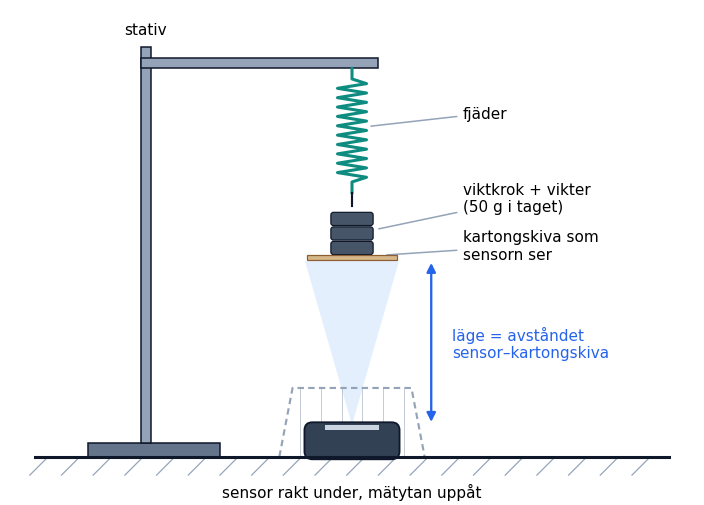

1. Häng fjädern i stativet och viktkroken i fjädern. Tejpa fast en kartongskiva, ungefär 10 cm i diameter, under viktkroken – den ger sensorn en bra yta att mäta mot.
2. Lägg sensorn på golvet rakt under kartongskivan, med mätytan uppåt. Avståndet ska vara minst 0,3 m.
3. **Referensläge:** låt viktkroken hänga stilla utan extra vikter. Mät några sekunder och läs av läget, alltså avståndet till sensorn. Hoppar värdet lite, använd medelvärdet.
4. Lägg på 50 g i taget. Vänta tills vikten hänger stilla, mät och läs av läget varje gång.
5. Sluta innan fjädern blir mycket utdragen – den ska gå tillbaka när ni tar bort vikterna.
6. Skriv in resultaten i cellen nedan: massan ni har lagt på (0 för referensläget) och läget i meter.

> **Tänk på:** Ljudkonen från sensorn ska bara träffa kartongskivan – inte stativet eller bordskanten.

In [ ]:
#@title B2. Skriv in era mätvärden { display-mode: "form" }
#@markdown Skriv talen med mellanslag emellan. Både 0,520 och 0.520 fungerar.
anvand_exempeldata_B = False #@param {type:"boolean"}
#@markdown **Pålagd massa i gram** – börja med 0 för referensläget:
palagd_massa_g = "" #@param {type:"string"}
#@markdown **Läget i meter** (avståndet sensor–kartongskiva) för varje massa:
lage_m = "" #@param {type:"string"}
#@markdown **Tyngdaccelerationen** $g$ i N/kg – byt gärna till ert eget värde från del A:
g_text = "9,82" #@param {type:"string"}
g = las_tal(g_text)[0]

if anvand_exempeldata_B:
    massa_B, lage_B = exempel_fjader()
    print("Exempeldata används.")
else:
    if not str(palagd_massa_g).strip() or not str(lage_m).strip():
        raise ValueError("Skriv in era mätvärden i fälten ovan – eller kryssa i anvand_exempeldata_B.")
    massa_B, lage_B = las_tal(palagd_massa_g), las_tal(lage_m)
massa_B, lage_B = np.array(massa_B, float), np.array(lage_B, float)

if len(massa_B) != len(lage_B):
    raise ValueError(f"Ni har skrivit {len(massa_B)} massor men {len(lage_B)} lägen. Det ska vara lika många.")
if len(massa_B) < 4:
    raise ValueError("Ni behöver minst fyra mätningar: referensläget och tre massor till.")
if massa_B[0] != 0:
    raise ValueError("Den första massan ska vara 0 – det är referensläget.")
if np.all(lage_B > 5):
    lage_B = lage_B / 100
    print("Lägena såg ut att vara i centimeter – jag har räknat om dem till meter.")
print(f"{len(massa_B)} mätningar inlästa. Referensläge: {tal(lage_B[0], 3)} m.")

### B3. Från mätvärden till kraft och förlängning
När vikterna hänger stilla drar fjädern uppåt lika hårt som tyngdkraften drar nedåt. Den extra kraften i fjädern är alltså lika stor som **tyngden av vikterna ni har lagt på**: $F = m \cdot g$.

**Förlängningen** är hur mycket längre fjädern har blivit jämfört med referensläget: $\Delta l$ = läget vid referensen − läget nu.

In [ ]:
#@title B3. Kraft och förlängning { display-mode: "form" }
F_B = massa_B / 1000 * g
dl_B = lage_B[0] - lage_B
if np.mean(dl_B[1:]) < 0:
    dl_B = -dl_B
    print("Läget ökade när vikterna sjönk – sensorn sitter troligen ovanför. Jag har bytt tecken på förlängningen.")

tabell = pd.DataFrame({"Pålagd massa (g)": massa_B.astype(int), "Kraft F (N)": F_B, "Förlängning Δl (m)": dl_B})
display(tabell.style.format({"Kraft F (N)": "{:.3f}", "Förlängning Δl (m)": "{:.3f}"}, decimal=",").hide(axis="index"))

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(dl_B, F_B, "o", color=TURK, ms=7)
ax.set_xlabel("förlängning $\\Delta l$ (m)"); ax.set_ylabel("kraft $F$ (N)")
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.set_title("Mätpunkterna", loc="left", fontsize=11)
svenska_axlar(ax)
plt.tight_layout()
plt.show()

**B3.** Ligger punkterna ungefär på en rät linje genom origo? Vad betyder det för sambandet mellan kraften och förlängningen?

**Ert svar:**

### B4. Träningsdata och testdata
Ni ska bestämma $k$ med de flesta mätpunkterna – **träningsdata** – och spara några för att testa modellen efteråt – **testdata**. Välj vilka massor som ska vara testdata, till exempel två i mitten.

> **Koppling till maskininlärning:** En modell ska fungera på ny data, inte bara på den data den har tränats på. Därför sparar man alltid testdata som modellen inte får se.

In [ ]:
#@title B4. Välj testdata { display-mode: "form" }
testmassor_g = "150 250" #@param {type:"string"}
test_lista = las_tal(testmassor_g) if str(testmassor_g).strip() else []
ar_test = np.isin(massa_B, test_lista)
ar_trann = (~ar_test) & (massa_B > 0)
if ar_trann.sum() < 2:
    raise ValueError("Ni behöver minst två träningspunkter. Välj färre testmassor.")
dl_tr, F_tr = dl_B[ar_trann], F_B[ar_trann]
dl_te, F_te, m_te = dl_B[ar_test], F_B[ar_test], massa_B[ar_test]
if ar_test.sum() == 0:
    print("Ingen av testmassorna finns bland era mätningar – skriv massor som ni har mätt.")
print(f"Träningsdata: {ar_trann.sum()} punkter. Testdata: {ar_test.sum()} punkter.")
print("Referenspunkten (0, 0) används inte – den ligger alltid på linjen och säger inget om k.")

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(dl_tr, F_tr, "o", color=TURK, ms=8, label="träningsdata")
ax.plot(dl_te, F_te, "s", mfc="white", mec=ORANGE, mew=2, ms=9, label="testdata (sparas)")
ax.set_xlabel("förlängning $\\Delta l$ (m)"); ax.set_ylabel("kraft $F$ (N)")
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
svenska_axlar(ax)
plt.tight_layout()
plt.show()

### B5. Gissa $k$ – och se förlusten
Modellen för fjädern är

$$F_{\text{fjäder}} = k \cdot \Delta l$$

Den har en enda parameter: fjäderkonstanten $k$. Dra i reglaget och se hur linjen ändras. De röda strecken visar hur långt varje träningspunkt ligger från linjen.

**Förlusten** är medelvärdet av strecken i kvadrat – **medelkvadratfelet**. Ju mindre förlust, desto bättre stämmer modellen med datan. Förlusten har enheten N², eftersom felen i newton kvadreras.

**Uppgift:** Hitta det $k$ som ger så liten förlust som möjligt. Skriv upp ert bästa $k$ och förlusten.

**Ert bästa k och förlusten:**

In [ ]:
#@title B5. Gissa k { run: "auto", display-mode: "form" }
k_gissning = 20 #@param {type:"slider", min:1, max:200, step:0.5}
L_gissning = forlust(k_gissning, dl_tr, F_tr)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
x_max = dl_B.max() * 1.1
ax.plot([0, x_max], [0, k_gissning * x_max], color=ORANGE, lw=2.5, label=f"modell: $F$ = {tal(k_gissning, 1)} · $\\Delta l$")
for x, y in zip(dl_tr, F_tr):
    ax.plot([x, x], [y, k_gissning * x], color=ROD, lw=2)
ax.plot(dl_tr, F_tr, "o", color=TURK, ms=8, label="träningsdata", zorder=3)
ax.set_xlim(0, x_max); ax.set_ylim(0, F_B.max() * 1.35)
ax.set_xlabel("förlängning $\\Delta l$ (m)"); ax.set_ylabel("kraft $F$ (N)")
ax.text(0.97, 0.06, f"förlust = {sig(L_gissning)} N²", transform=ax.transAxes, ha="right", fontsize=13,
        bbox=dict(boxstyle="round", fc="white", ec=ORANGE))
ax.legend(loc="upper left")
svenska_axlar(ax)
plt.tight_layout()
plt.show()
print(f"k = {tal(k_gissning, 1)} N/m ger förlusten {sig(L_gissning)} N².")

### B6. Förlustkurvan
I stället för att gissa kan datorn räkna ut förlusten för hundratals värden på $k$ och rita **förlustkurvan**. Den bästa skattningen av $k$ är där kurvan har sitt **minimum**.

> **Koppling till maskininlärning:** Att träna en modell betyder att leta upp minimum i förlusten. I en senare labb får ni se hur datorn hittar minimum steg för steg, utan att räkna ut hela kurvan.

In [ ]:
#@title B6. Förlustkurvan { display-mode: "form" }
k_bast = basta_k(dl_tr, F_tr)
L_bast = forlust(k_bast, dl_tr, F_tr)
lo = max(min(0.4 * k_bast, 0.8 * k_gissning), 0.01)
hi = max(1.6 * k_bast, 1.2 * k_gissning)
kk = np.linspace(lo, hi, 400)
LL = np.array([forlust(k, dl_tr, F_tr) for k in kk])

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(kk, LL, color=INK, lw=2, label="förlustkurvan")
ax.plot([k_gissning], [L_gissning], "o", color=ORANGE, ms=10, label="er gissning", zorder=3)
ax.plot([k_bast], [L_bast], "o", color=BLA, ms=10, label="minimum", zorder=3)
ax.axvline(k_bast, color=BLA, ls="--", lw=1)
ax.annotate(f"minimum vid k = {tal(k_bast, 1)} N/m", (k_bast, L_bast), textcoords="offset points", xytext=(10, 40), color=BLA,
            arrowprops=dict(arrowstyle="->", color=BLA))
ax.set_xlabel("fjäderkonstant $k$ (N/m)"); ax.set_ylabel("förlust (N²)")
ax.set_ylim(bottom=0)
ax.legend(loc="upper center")
svenska_axlar(ax)
plt.tight_layout()
plt.show()
print(f"Bästa skattning: k = {tal(k_bast, 1)} N/m  (förlust {sig(L_bast)} N²)")
print(f"Er gissning:     k = {tal(k_gissning, 1)} N/m  (förlust {sig(L_gissning)} N²)")

**B6.** Hur nära det bästa $k$ kom er gissning? Vilken form har förlustkurvan – känner ni igen den från del A?

**Ert svar:**

### B7. Testa modellen
Nu används modellen på testdatan, som den inte har sett. För varje testmassa räknar modellen ut den förlängning den förutsäger, $\Delta l = \dfrac{F}{k}$. Jämför med det ni mätte.

In [ ]:
#@title B7. Testa modellen { display-mode: "form" }
if len(dl_te) == 0:
    print("Ingen testdata är vald – gå tillbaka till B4.")
else:
    dl_pred = F_te / k_bast
    tab = pd.DataFrame({"Massa (g)": m_te.astype(int), "Uppmätt Δl (cm)": dl_te * 100, "Förutsagd Δl (cm)": dl_pred * 100,
                        "Skillnad (mm)": (dl_pred - dl_te) * 1000, "Skillnad (%)": (dl_pred - dl_te) / dl_te * 100})
    display(tab.style.format({c: "{:.2f}" for c in tab.columns if c != "Massa (g)"}, decimal=",").hide(axis="index"))

    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    x_max = dl_B.max() * 1.1
    ax.plot([0, x_max], [0, k_bast * x_max], color=BLA, lw=2, label=f"modell: $F$ = {tal(k_bast, 1)} · $\\Delta l$")
    ax.plot(dl_tr, F_tr, "o", color=TURK, ms=8, label="träningsdata")
    ax.plot(dl_te, F_te, "s", mfc="white", mec=ORANGE, mew=2, ms=10, label="testdata, uppmätt")
    ax.plot(dl_pred, F_te, "x", color=ROD, ms=10, mew=2.5, label="testdata, förutsagd")
    ax.set_xlim(0, x_max); ax.set_ylim(bottom=0)
    ax.set_xlabel("förlängning $\\Delta l$ (m)"); ax.set_ylabel("kraft $F$ (N)")
    ax.legend(loc="upper left")
    svenska_axlar(ax)
    plt.tight_layout()
    plt.show()
    print(f"Modellens förutsägelser skiljer sig i genomsnitt {tal(np.mean(np.abs(dl_pred - dl_te)) * 1000, 1)} mm från mätningarna.")

### Frågor till del B
**B8.** Hur bra förutsade modellen testdatan? Varför är det viktigt att testa en modell på data som den inte har sett?

**B9.** Använd modellen för att förutsäga förlängningen om ni hänger 2 kg i fjädern. *Prova inte i verkligheten!* Tror ni på förutsägelsen? Motivera.

**B10.** Skriv in ert eget värde på $g$ från del A i B2 och kör om cellerna B2–B7. Hur ändras $k$? Förklara varför.

**B11.** Vilka felkällor finns i del B? Vilken tror ni påverkar resultatet mest?

**Era svar:**

---
## Del C (extra) – Den svängande vikten
Häng på 200 g, dra ner vikten ungefär 2 cm och släpp. Mät i 5 sekunder och exportera som CSV. Ladda in filen med cellen nedan – eller använd exempeldata.

In [ ]:
#@title C. Den svängande vikten { display-mode: "form" }
anvand_exempeldata_C = False #@param {type:"boolean"}
korning_C = 1 #@param {type:"integer"}
data_C = hamta_data(anvand_exempeldata_C, exempel_svangning, korning_C)
tC, sC, vC = data_C["t"].to_numpy(), data_C["s"].to_numpy(), data_C["v"].to_numpy()

rorelse = np.where(np.abs(vC) > 0.08)[0]
t_fran = tC[max(rorelse[0] - 2, 0)] if len(rorelse) else tC[0]
m = tC >= t_fran
vs = pd.Series(vC[m]).rolling(3, center=True, min_periods=1).mean().to_numpy()
i0 = np.where(np.sign(vs[:-1]) * np.sign(vs[1:]) < 0)[0]
t_noll = (tC[m][i0] + tC[m][i0 + 1]) / 2
medel = sC[m].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True)
ax1.plot(tC, sC, "-", color=INK, lw=1.5)
ax1.axhline(medel, color=TURK, ls="--", lw=1.5, label=f"mittläge {tal(medel, 3)} m")
ax2.plot(tC, vC, "-", color=BLA, lw=1.5)
ax2.axhline(0, color=GRA, lw=1)
for tn in t_noll:
    for ax in (ax1, ax2):
        ax.axvline(tn, color=ORANGE, ls=":", lw=1.5)
ax1.set_ylabel("läge $s$ (m)"); ax2.set_ylabel("hastighet $v$ (m/s)"); ax2.set_xlabel("tid $t$ (s)")
ax1.legend(loc="lower right")
ax1.set_title("De orange linjerna visar när hastigheten är noll", loc="left", fontsize=11)
svenska_axlar(ax1, ax2)
plt.tight_layout()
plt.show()
print(f"Mittläget (medelvärdet av läget efter släppet): {tal(medel, 3)} m")

**C1.** Var i $s$–$t$-grafen är hastigheten noll? Var är farten störst? Hur syns det på lutningen i $s$–$t$-grafen?

**C2.** Jämför mittläget med läget ni mätte i del B för 200 g. Vad lägger ni märke till?

**Era svar:**

---
## Sammanfattning

In [ ]:
#@title Sammanfattning { display-mode: "form" }
rader = []
try:
    rader.append(f"Del A: g ≈ {tal(g_v)} m/s² (från hastigheten) och {tal(g_s)} m/s² (från läget)")
except NameError:
    rader.append("Del A: inte klar")
try:
    rader.append(f"Del B: k ≈ {tal(k_bast, 1)} N/m, tränat på {len(dl_tr)} mätpunkter")
    if len(dl_te):
        rader.append(f"        testfel i genomsnitt {tal(np.mean(np.abs(F_te / k_bast - dl_te)) * 1000, 1)} mm")
except NameError:
    rader.append("Del B: inte klar")
print("\n".join(rader))

**S1.** Vilken modell och vilken parameter hade ni i del A? I del B?

**S2.** Beskriv med egna ord vad parameterskattning är.

**S3.** Ge ett exempel från vardagen där en dator skattar parametrar ur data.

**S4.** En stor maskininlärningsmodell kan ha miljarder parametrar. Vad skiljer dem från parametrarna $g$ och $k$ som ni har skattat idag?

**Era svar:**

---
**Lämna in:** Öppna uppgiften i Classroom och välj *Lägg till eller skapa* → *Google Drive*. Välj gruppens kopia av anteckningsboken och klicka på *Lämna in*. Alla i gruppen lämnar in samma anteckningsbok.